# 036 — KNN

**Objetivo:** Pesquisa 3-fold estratificada no treino: n_neighbors 5, 15, 31 e pesos uniform/distance. A normalização numérica e imputação/one-hot são ajustadas dentro de cada fold.

A preparação é a central do projeto; AGE_RANGE, PID, HHID, PROXY e COUNTRY não entram nas features. Divisão estratificada fixa já existente (8.769/2.193, seed 42). A configuração é selecionada só dentro do treino; a validação fixa é desenvolvimento, não teste independente. Execução sequencial, uma thread, checkpoints validados por dados/código/parâmetros/versões. Kaggle fica em branco.

**Conclusão prevista:** Seleciona exclusivamente pela Macro F1 média CV; distância em one-hot é uma limitação esperada.

036: candidato 1/6, fold 1/3


036: candidato 1/6, fold 2/3


036: candidato 1/6, fold 3/3


036: candidato 2/6, fold 1/3


036: candidato 2/6, fold 2/3


036: candidato 2/6, fold 3/3


... (13 outputs left out)

,configuração,Macro F1 CV média,DP folds,accuracy CV média
0,"n_neighbors=5, weights=uniform",0.284673,0.014712,0.295359
1,"n_neighbors=5, weights=distance",0.303391,0.010654,0.303683
2,"n_neighbors=15, weights=uniform",0.305292,0.017984,0.321701
3,"n_neighbors=15, weights=distance",0.317943,0.017773,0.330254
4,"n_neighbors=31, weights=uniform",0.316808,0.017130,0.337439
5,"n_neighbors=31, weights=distance",0.320828,0.013331,0.339834


Selecionado apenas no treino: {'params': {'n_neighbors': 31, 'weights': 'distance'}, 'label': 'n_neighbors=31, weights=distance', 'cv_macro_f1': [0.3233929949620101, 0.3064007339423076, 0.33268902281415214], 'cv_macro_f1_mean': 0.3208275839061566, 'cv_macro_f1_std': 0.013330586384946008, 'cv_accuracy_mean': 0.3398335043904664, 'cv_train_macro_f1_mean': 1.0, 'folds': [{'train': {'macro_f1': 1.0, 'accuracy': 1.0, 'per_class': [{'classe': 0, 'escalão': '15–17 anos', 'F1': 1.0, 'recall': 1.0, 'support': 110}, {'classe': 1, 'escalão': '18–19 anos', 'F1': 1.0, 'recall': 1.0, 'support': 92}, {'classe': 2, 'escalão': '20–24 anos', 'F1': 1.0, 'recall': 1.0, 'support': 213}, {'classe': 3, 'escalão': '25–29 anos', 'F1': 1.0, 'recall': 1.0, 'support': 201}, {'classe': 4, 'escalão': '30–34 anos', 'F1': 1.0, 'recall': 1.0, 'support': 240}, {'classe': 5, 'escalão': '35–39 anos', 'F1': 1.0, 'recall': 1.0, 'support': 345}, {'classe': 6, 'escalão': '40–44 anos', 'F1': 1.0, 'recall': 1.0, 'support': 458}

,classe,escalão,F1,recall,support,destacada
0,0,15–17 anos,0.478261,0.804878,41,
1,1,18–19 anos,0.101695,0.088235,34,CHAVE
2,2,20–24 anos,0.270270,0.250000,80,
3,3,25–29 anos,0.074766,0.053333,75,
4,4,30–34 anos,0.145985,0.111111,90,
5,5,35–39 anos,0.331081,0.379845,129,
6,6,40–44 anos,0.224599,0.244186,172,CHAVE
7,7,45–49 anos,0.258065,0.254335,173,
8,8,50–54 anos,0.464589,0.453039,181,
9,9,55–59 anos,0.588235,0.541872,203,


Submissão: {'path': None, 'reason': 'Candidato exploratório abaixo do controlo 025/028; não gerado CSV.', 'differences': {}}


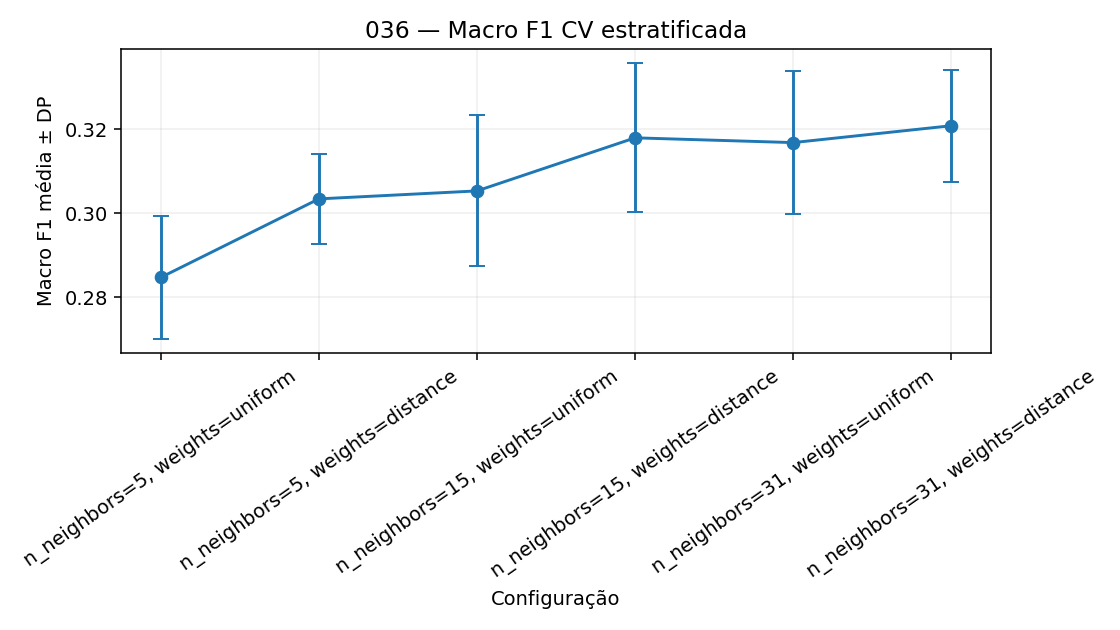

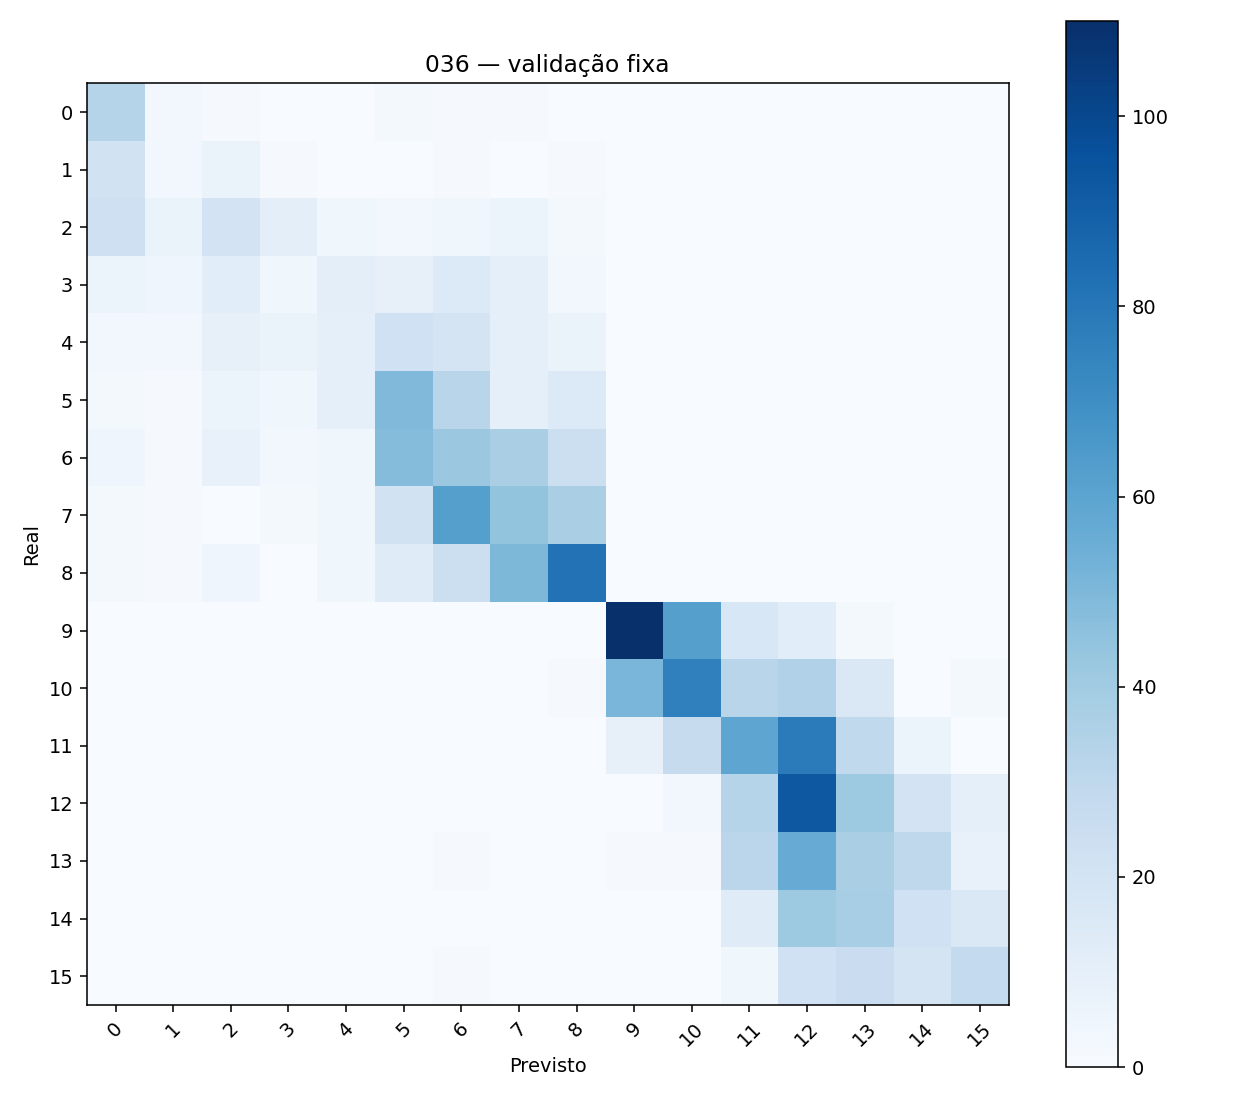

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_035_055.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_035_055 import run_experiment

result = run_experiment("036")
print('Experiência:', result['experiment'])
print('Estado:', result.get('status', 'executado'))
print('Configuração:', result.get('configuration'))
print('Versões:', result.get('versions'))
print('Tempo de ajuste (s):', result.get('elapsed_model_fit_seconds', 'n/a'))
print('Kaggle score: —')
if result.get('candidates'):
    if result['experiment'] == '035':
        rows = [{'configuração': x['strategy'], 'F1 treino': x['train']['macro_f1'], 'F1 validação': x['validation']['macro_f1'], 'accuracy validação': x['validation']['accuracy']} for x in result['candidates']]
    else:
        rows = [{'configuração': x['label'], 'Macro F1 CV média': x['cv_macro_f1_mean'], 'DP folds': x['cv_macro_f1_std'], 'accuracy CV média': x['cv_accuracy_mean']} for x in result['candidates']]
    display(pd.DataFrame(rows))
if result.get('selected_internally'):
    print('Selecionado apenas no treino:', result['selected_internally'])
if result.get('fixed_metrics'):
    fixed = result['fixed_metrics']
    print('Macro F1 treino/validação:', fixed['train']['macro_f1'], fixed['validation']['macro_f1'])
    print('Accuracy treino/validação:', fixed['train']['accuracy'], fixed['validation']['accuracy'])
    classes = pd.DataFrame(fixed['validation']['per_class'])
    classes['destacada'] = classes['classe'].map({1: 'CHAVE', 6: 'CHAVE', 13: 'CHAVE'}).fillna('')
    display(classes[['classe', 'escalão', 'F1', 'recall', 'support', 'destacada']])
if result.get('warnings'):
    print('Avisos (incluindo convergência):')
    for warning in result['warnings']:
        print(warning)
if result.get('memory_preflight'):
    print('Preflight de memória antes da densificação:', result['memory_preflight'])
if result.get('submission') is not None:
    print('Submissão:', result['submission'])
for key in ('curves', 'confusion_matrix'):
    if result.get(key):
        display(Image(filename=str(root / result[key])))
